<a href="https://colab.research.google.com/github/bahramzada/python-data-projects/blob/main/Airlines_Flights_Dataset_for_Different_Cities.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!wget https://raw.githubusercontent.com/HuseynA28/dataset_portfolio/refs/heads/main/airlines_flights_data.csv

--2025-09-20 07:47:48--  https://raw.githubusercontent.com/HuseynA28/dataset_portfolio/refs/heads/main/airlines_flights_data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 24946485 (24M) [text/plain]
Saving to: ‘airlines_flights_data.csv’

airlines_flights_da 100%[===================>]  23.79M  34.7MB/s    in 0.7s    

2025-09-20 07:47:52 (34.7 MB/s) - ‘airlines_flights_data.csv’ saved [24946485/24946485]



In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('/content/airlines_flights_data.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   index             300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [6]:
df.describe()

,index,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [7]:
df.head()

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


- Datasetdə hansı aviaşirkətlər var və onların tezlikləri nə qədərdir?

- Which airlines are in the dataset and what are their frequencies?



In [8]:
df['airline'].value_counts()

,count
airline,
Vistara,127859
Air_India,80892
Indigo,43120
GO_FIRST,23173
AirAsia,16098
SpiceJet,9011


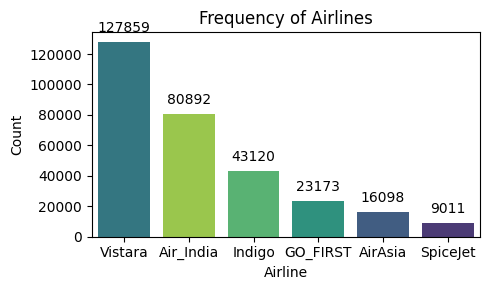

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5, 3))
ax = sns.countplot(
    data=df,
    x='airline',
    hue='airline', #for seaborn update
    order=df['airline'].value_counts().index,
    palette='viridis',
    legend=False
)
plt.title('Frequency of Airlines')
plt.xlabel('Airline')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(
        str(int(p.get_height())),
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=10,
        color='black',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

- Gediş vaxtı və Gəliş vaxtını təmsil edən Bar Qrafikləri göstərin.
- Display Bar Charts representing **Departure Time** and **Arrival Time**.

In [10]:
df.departure_time.value_counts()

,count
departure_time,
Morning,71146
Early_Morning,66790
Evening,65102
Night,48015
Afternoon,47794
Late_Night,1306


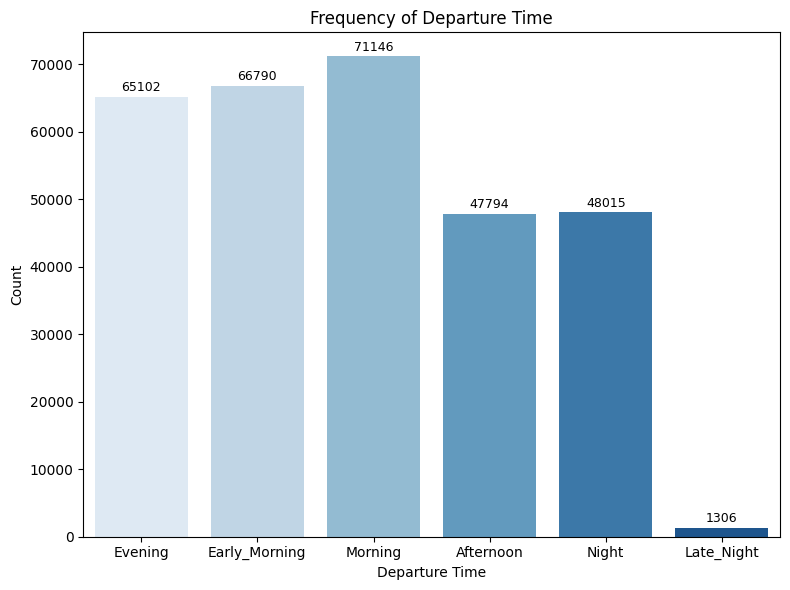

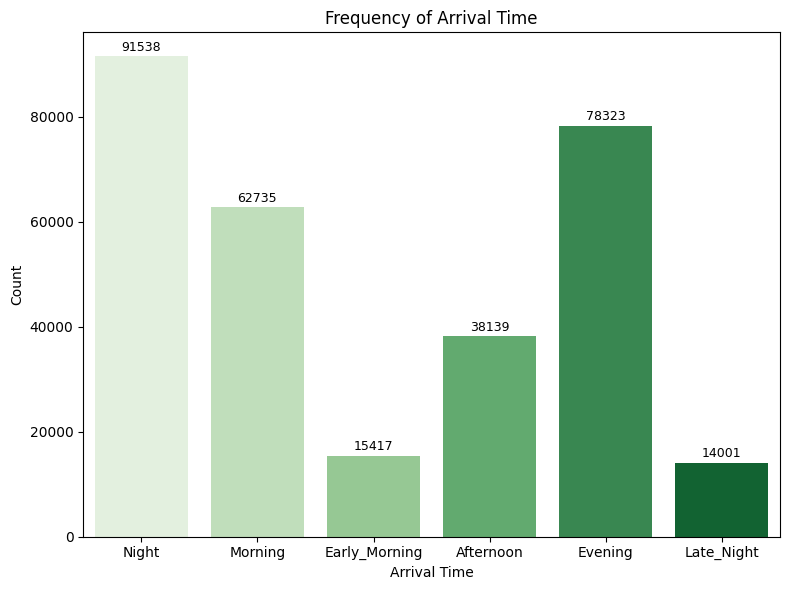

In [11]:
# Barplot for Departure Time
plt.figure(figsize=(8, 6))
ax1 = sns.countplot(x='departure_time', data=df, palette='Blues', hue='departure_time', legend=False)
for p in ax1.patches:
    ax1.annotate(int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 2), textcoords='offset points')
plt.title('Frequency of Departure Time')
plt.xlabel('Departure Time')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Barplot for Arrival Time
plt.figure(figsize=(8, 6))
ax2 = sns.countplot(x='arrival_time', data=df, palette='Greens', hue='arrival_time', legend=False)
for p in ax2.patches:
    ax2.annotate(int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 2), textcoords='offset points')
plt.title('Frequency of Arrival Time')
plt.xlabel('Arrival Time')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

- Mənbə Şəhəri və Təyinat Şəhəri təmsil edən Bar Qrafikləri göstərin.
- Display Bar Charts representing **Source City** and **Destination City**.

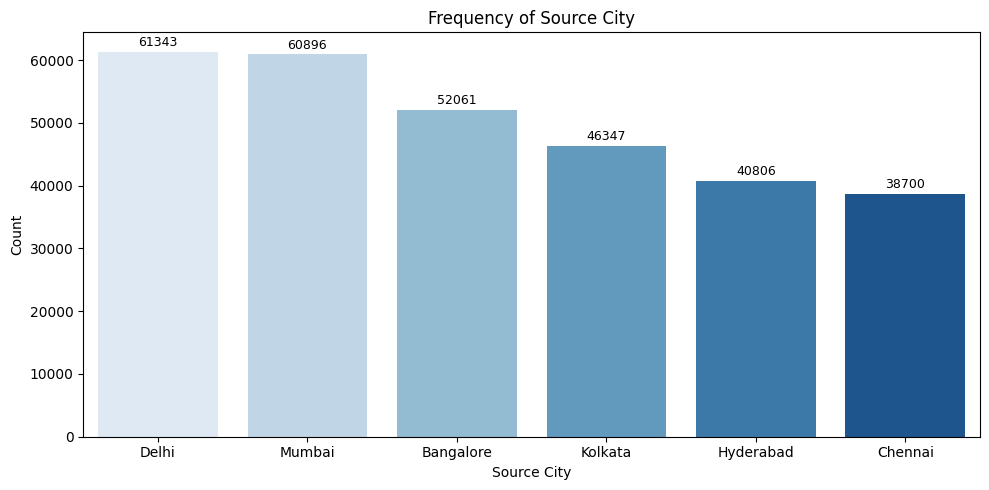

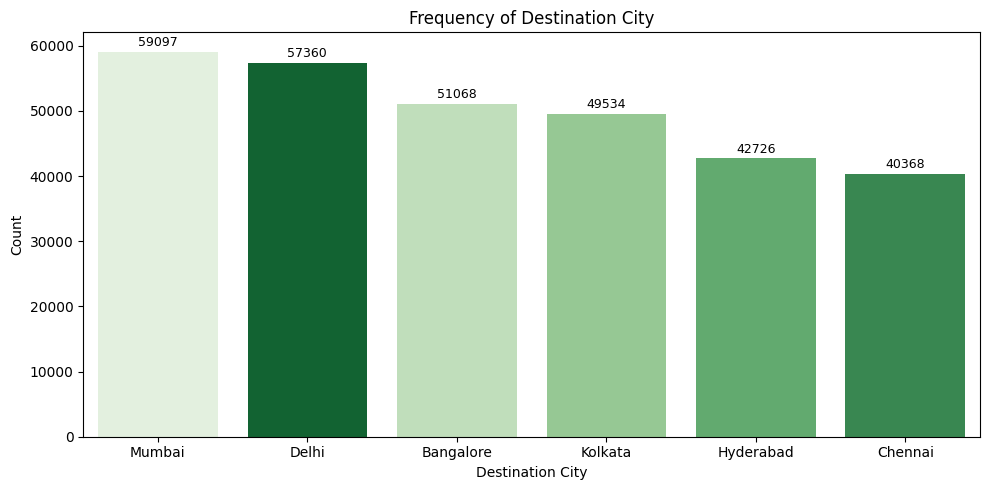

In [12]:
# Barplot for Source City
plt.figure(figsize=(10, 5))
ax1 = sns.countplot(x='source_city', data=df, palette='Blues',hue = 'source_city', order=df['source_city'].value_counts().index, legend=False)
for p in ax1.patches:
    ax1.annotate(int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 2), textcoords='offset points')
plt.title('Frequency of Source City')
plt.xlabel('Source City')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Barplot for Destination City
plt.figure(figsize=(10, 5))
ax2 = sns.countplot(x='destination_city', data=df, palette='Greens',hue = 'destination_city', order=df['destination_city'].value_counts().index, legend=False)
for p in ax2.patches:
    ax2.annotate(int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 2), textcoords='offset points')
plt.title('Frequency of Destination City')
plt.xlabel('Destination City')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

- Qiymət aviaşirkətlərə görə dəyişirmi?
- Does the price vary by airline?

In [13]:
avg_price_by_airline = df.groupby('airline')['price'].mean().reset_index()
avg_price_by_airline

,airline,price
0,AirAsia,4091.072742
1,Air_India,23507.019112
2,GO_FIRST,5652.007595
3,Indigo,5324.216303
4,SpiceJet,6179.278881
5,Vistara,30396.536302


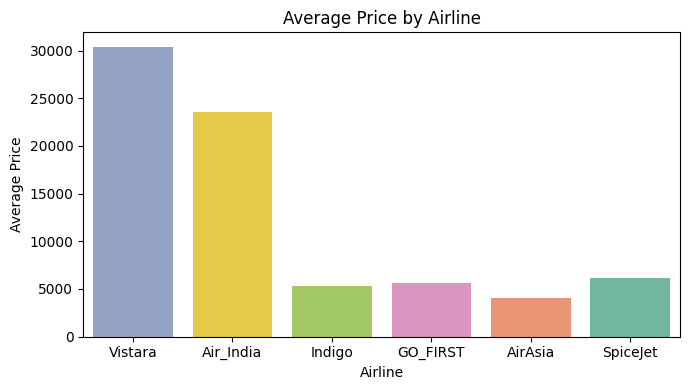

In [14]:
plt.figure(figsize=(7, 4))
sns.barplot(
    x='airline',
    y='price',
    data=df,
    order=df['airline'].value_counts().index,
    palette='Set2',
    hue='airline',
    legend=False,
    errorbar=None
)
plt.title('Average Price by Airline')
plt.xlabel('Airline')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

- Bilet qiyməti gediş vaxtı və gəliş vaxtına əsasən dəyişirmi?
- Does the ticket price vary based on departure time and arrival time?

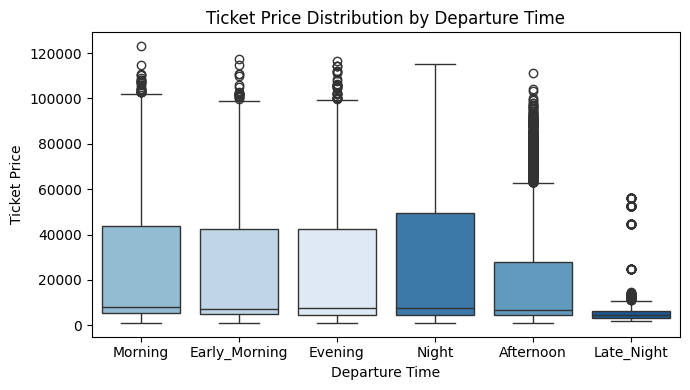

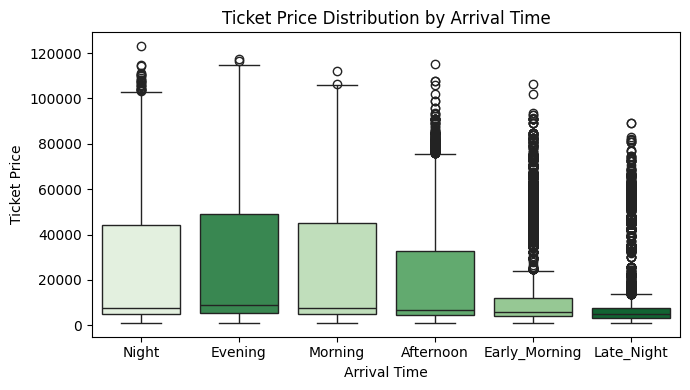

In [15]:
# Boxplot for Departure Time
plt.figure(figsize=(7, 4))
sns.boxplot(x='departure_time', y='price',hue = 'departure_time' , data=df, palette='Blues', order=df['departure_time'].value_counts().index)
plt.title('Ticket Price Distribution by Departure Time')
plt.xlabel('Departure Time')
plt.ylabel('Ticket Price')
plt.tight_layout()
plt.show()

# Boxplot for Arrival Time
plt.figure(figsize=(7, 4))
sns.boxplot(x='arrival_time', y='price', data=df,hue = 'arrival_time' ,palette='Greens', order=df['arrival_time'].value_counts().index)
plt.title('Ticket Price Distribution by Arrival Time')
plt.xlabel('Arrival Time')
plt.ylabel('Ticket Price')
plt.tight_layout()
plt.show()

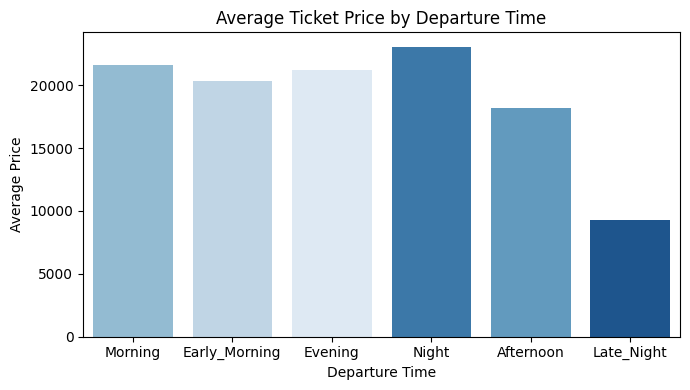

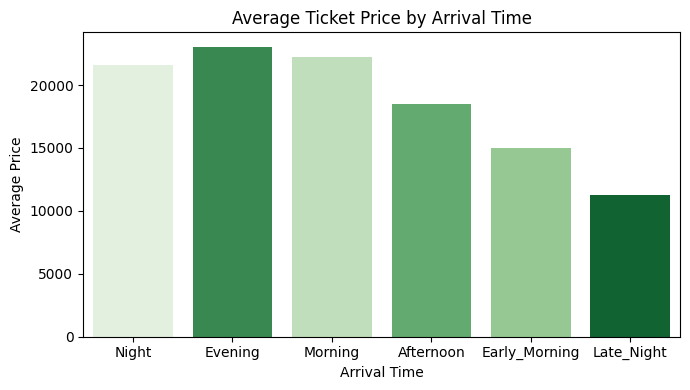

In [16]:
plt.figure(figsize=(7, 4))
sns.barplot(x='departure_time', y='price', data=df, palette='Blues',hue = 'departure_time' , order=df['departure_time'].value_counts().index, errorbar=None)
plt.title('Average Ticket Price by Departure Time')
plt.xlabel('Departure Time')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.barplot(x='arrival_time', y='price', data=df, palette='Greens',hue = 'arrival_time' , order=df['arrival_time'].value_counts().index, errorbar=None)
plt.title('Average Ticket Price by Arrival Time')
plt.xlabel('Arrival Time')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

- Qiymət mənbə və təyinatın dəyişməsi ilə necə dəyişir?
- How does the price vary with changes in source and destination?

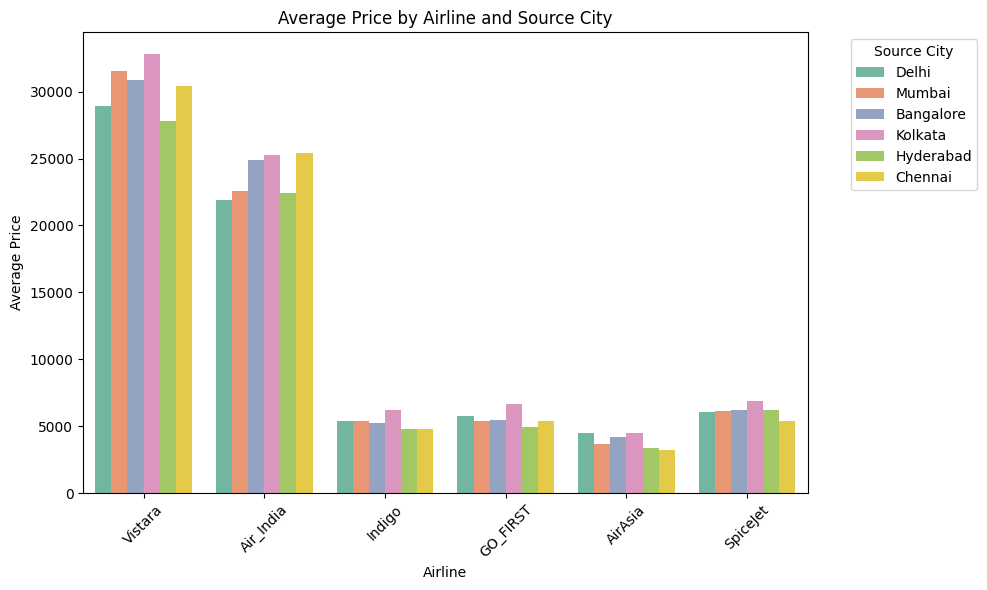

In [17]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x='airline',
    y='price',
    hue='source_city',  # or use 'destination_city' or another categorical column
    data=df,
    order=df['airline'].value_counts().index,
    palette='Set2',
    errorbar=None
)
plt.title('Average Price by Airline and Source City')
plt.xlabel('Airline')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.legend(title='Source City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

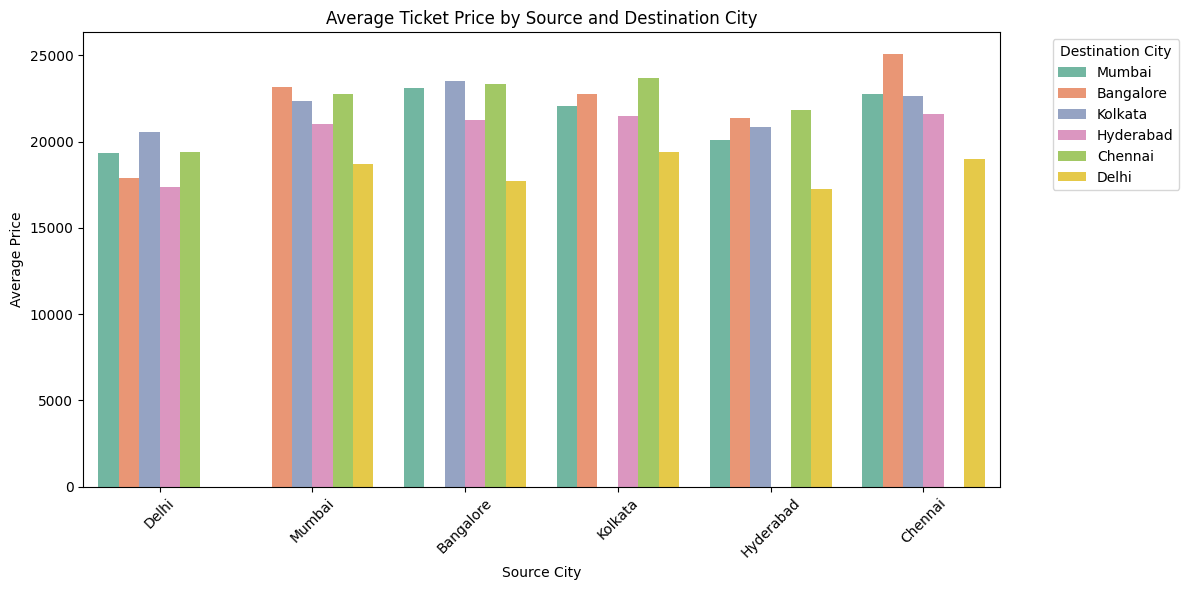

In [18]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x='source_city',
    y='price',
    hue='destination_city',  # Add hue
    data=df,
    palette='Set2',
    errorbar=None
)
plt.title('Average Ticket Price by Source and Destination City')
plt.xlabel('Source City')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.legend(title='Destination City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()



> Qruplaşdırılmış sütun diaqramı orta bilet qiymətlərinin həm çıxış, həm də təyinat şəhərlərinə görə necə dəyişdiyini göstərir. Hər bir çıxış şəhəri üçün, təyinatdan asılı olaraq bilet qiymətləri fərqli olur və bu, bütün marşrutlarda səyahət xərclərinin eyni olmadığını vurğulayır. Qeyd etmək lazımdır ki, bəzi şəhər cütlüklərində orta qiymətlər daim yüksək olur, bu da həmin marşrutların digərlərinə nisbətən daha bahalı olduğunu göstərir. Bu analiz göstərir ki, həm çıxış, həm də təyinat şəhəri bilet qiymətlərinin müəyyən olunmasında mühüm rol oynayır və marşrutlara xas amillər aviaşirkətlərin qiymət siyasətinə təsir edə bilər.


> The grouped bar chart illustrates how average ticket prices fluctuate based on both the source and destination city pairings. Each source city displays a range of ticket prices depending on the destination, highlighting that travel costs are not uniform across all routes. Notably, some city combinations consistently yield higher average prices, indicating that certain routes are more expensive than others. This analysis reveals that both the city of departure and the city of arrival play significant roles in determining ticket pricing, suggesting that route-specific factors may influence airline pricing strategies.




- Biletlər uçuşdan cəmi 1 və ya 2 gün əvvəl alındıqda qiymət necə təsirlənir?
- How does the price change when tickets are purchased 1 or 2 days before the flight?

In [19]:
# Filter tickets purchased 1 or 2 days before the flight
df_last2days = df[df['days_left'].isin([1, 2])]

# Calculate average price for each group
avg_prices = df_last2days.groupby('days_left')['price'].mean().reset_index()
print(avg_prices)

   days_left         price
0          1  21591.867151
1          2  30211.299801


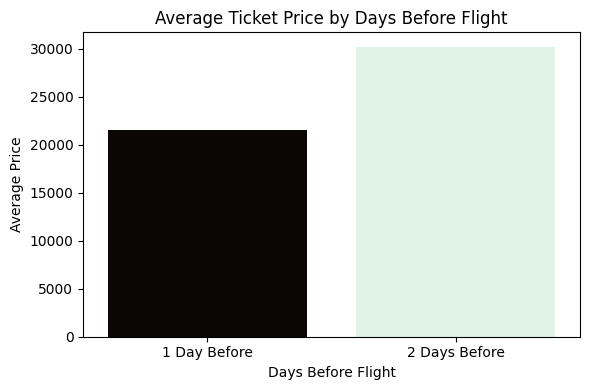

In [20]:
plt.figure(figsize=(6, 4))
sns.barplot(x='days_left', y='price',hue ='days_left' , data=avg_prices, palette='mako',legend=False)
plt.title('Average Ticket Price by Days Before Flight')
plt.xlabel('Days Before Flight')
plt.ylabel('Average Price')
plt.xticks([0, 1], ['1 Day Before', '2 Days Before'])
plt.tight_layout()
plt.show()

- Qiymət Ekonom və Biznes sinfi arasında necə dəyişir?
- How does the price vary between Economy and Business class?

In [26]:
avg_price_by_class = df.groupby('class')['price'].mean().reset_index()
avg_price_by_class

,class,price
0,Business,52540.081124
1,Economy,6572.342383


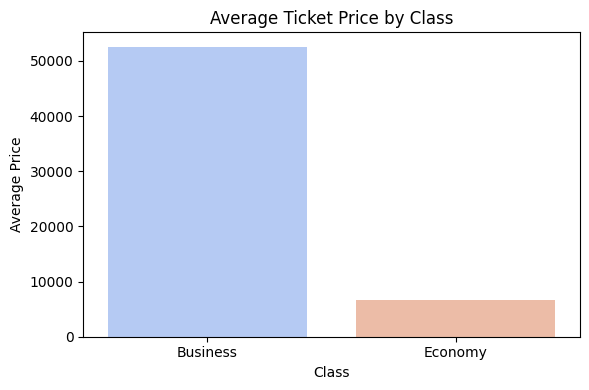

In [27]:
plt.figure(figsize=(6, 4))
sns.barplot(
    x='class',
    y='price',
    data=avg_price_by_class,
    hue = 'class',
    palette='coolwarm',
    errorbar=None
)
plt.title('Average Ticket Price by Class')
plt.xlabel('Class')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

- Datasetdəki uçuşların orta müddəti (duration) nə qədərdir və bu müddət sinflərə (Economy/Business) görə necə fərqlənir?
- What is the average duration of flights in the dataset, and how does this duration differ by class (Economy/Business)?

In [32]:
overall_avg_duration = df['duration'].mean()
print("Overall average flight duration:", overall_avg_duration)

Overall average flight duration: 12.221020812718846


In [30]:
avg_duration_by_class = df.groupby('class')['duration'].mean().reset_index()
print(avg_duration_by_class)

      class   duration
0  Business  13.704274
1   Economy  11.550060


- Dayancaq sayı (stops) qiymətə necə təsir edir? (Məsələn, zero, one, two_or_more duraklar üçün orta qiymətləri müqayisə edin.)
- How does the number of stops affect the price? (For example, compare the average prices for zero, one, and two_or_more stops.)

In [33]:
avg_price_by_stops = df.groupby('stops')['price'].mean().reset_index()
print(avg_price_by_stops)

         stops         price
0          one  22900.992482
1  two_or_more  14113.450775
2         zero   9375.938535


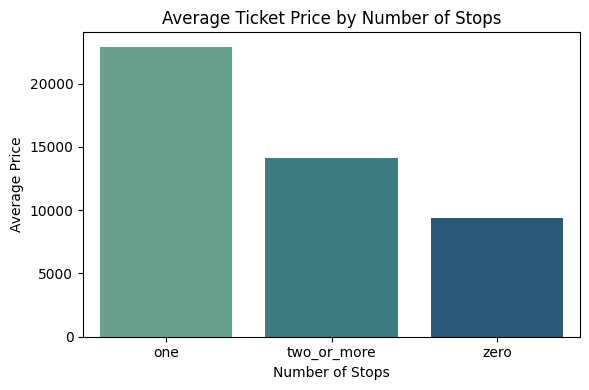

In [37]:
plt.figure(figsize=(6, 4))
sns.barplot(
    x='stops',
    y='price',
    data=avg_price_by_stops,
    hue = 'stops',
    palette='crest',
    errorbar=None
)
plt.title('Average Ticket Price by Number of Stops')
plt.xlabel('Number of Stops')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

- Günlər qalmış (days_left) dəyişkəninə görə qiymətin paylanması necədir? (Məsələn, 1-10 gün, 11-20 gün və s. qruplar üzrə qrafik və ya orta qiymətlər.)
- What is the price distribution based on the days_left variable? (For example, a graph or average prices for groups like 1-10 days, 11-20 days, etc.)

In [39]:
bins = [0, 10, 20, 30, 40, 50]
labels = ['1-10', '11-20', '21-30', '31-40', '41-50']
df['days_group'] = pd.cut(df['days_left'], bins=bins, labels=labels, right=True, include_lowest=True)

In [40]:
avg_price_by_days = df.groupby('days_group')['price'].mean().reset_index()
print(avg_price_by_days)

  days_group         price
0       1-10  26082.751717
1      11-20  21260.475515
2      21-30  19625.787849
3      31-40  19393.765657
4      41-50  19108.742210


/tmp/ipython-input-1089555877.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_price_by_days = df.groupby('days_group')['price'].mean().reset_index()


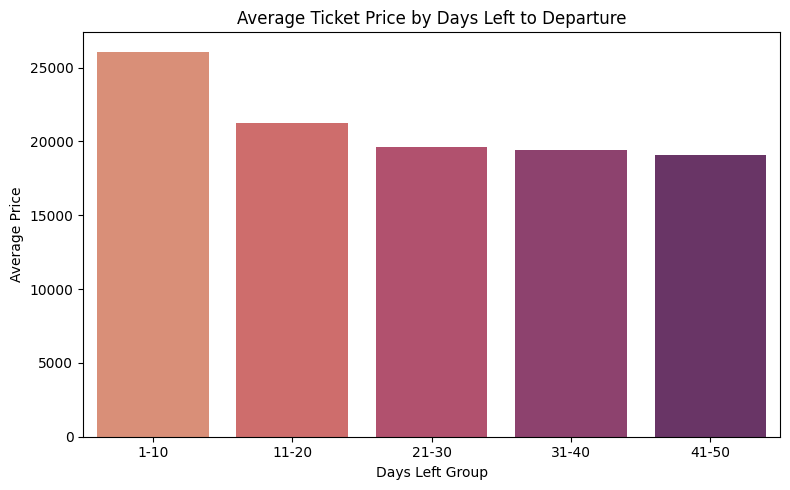

In [43]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='days_group',
    y='price',
    data=avg_price_by_days,
    hue = 'days_group',
    palette='flare'
)
plt.title('Average Ticket Price by Days Left to Departure')
plt.xlabel('Days Left Group')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

- Hansı mənbə şəhərdən (source_city) ən çox uçuş var və onların orta qiyməti nə qədərdir?
- Which source city has the most flights, and what is their average price?

In [44]:
most_flights_city = df['source_city'].value_counts().idxmax()
num_flights = df['source_city'].value_counts().max()

In [45]:
avg_price = df[df['source_city'] == most_flights_city]['price'].mean()

In [46]:
print(f"The source city with the most flights is {most_flights_city} ({num_flights} flights), and its average ticket price is {avg_price:.2f}.")

The source city with the most flights is Delhi (61343 flights), and its average ticket price is 18951.33.


In [47]:
top_cities = df['source_city'].value_counts().nlargest(5)

<class 'pandas.core.series.Series'>
Index: 5 entries, Delhi to Hyderabad
Series name: count
Non-Null Count  Dtype
--------------  -----
5 non-null      int64
dtypes: int64(1)
memory usage: 252.0+ bytes


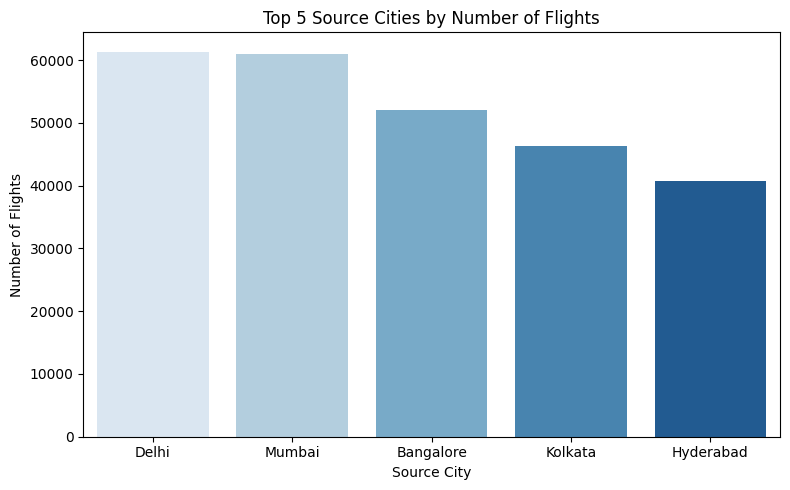

In [55]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x=top_cities.index,
    y=top_cities.values,
    palette='Blues',
    hue = top_cities.index

)
plt.title('Top 5 Source Cities by Number of Flights')
plt.xlabel('Source City')
plt.ylabel('Number of Flights')
plt.tight_layout()
plt.show()

- Biznes sinfində uçuşların ümumi sayı və orta qiyməti Econom sinfi ilə müqayisədə necədir?
- How do the total number of flights and the average price in Business class compare to Economy class?

In [56]:
class_stats = df.groupby('class').agg(
    total_flights=('class', 'count'),
    avg_price=('price', 'mean')
).reset_index()
print(class_stats)

      class  total_flights     avg_price
0  Business          93487  52540.081124
1   Economy         206666   6572.342383


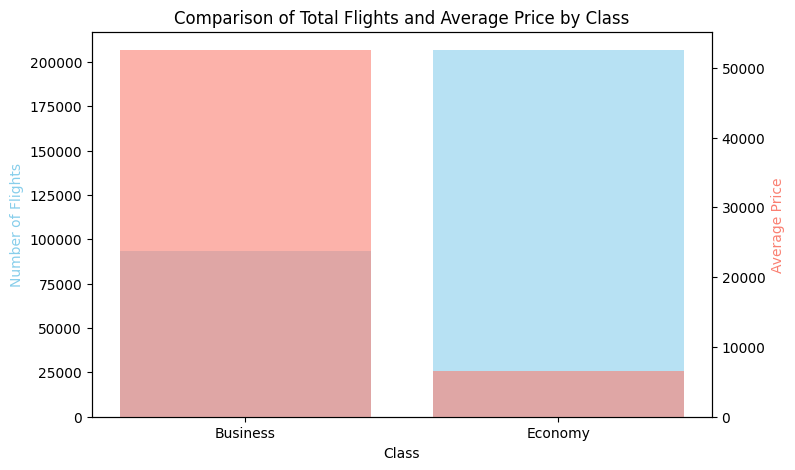

In [57]:
fig, ax1 = plt.subplots(figsize=(8,5))

# Bar for total flights
ax1.bar(class_stats['class'], class_stats['total_flights'], color='skyblue', alpha=0.6, label='Total Flights')
ax1.set_ylabel('Number of Flights', color='skyblue')
ax1.set_xlabel('Class')

# Bar for average price (on a second y-axis)
ax2 = ax1.twinx()
ax2.bar(class_stats['class'], class_stats['avg_price'], color='salmon', alpha=0.6, label='Avg Price')
ax2.set_ylabel('Average Price', color='salmon')

plt.title('Comparison of Total Flights and Average Price by Class')
plt.show()

- Datasetdəki ən bahalı və ən ucuz uçuşlar hansı aviaşirkətlərə və şəhərlərə aiddir? (Ən azı 5 nümunə verin.)
- Which airlines and cities do the most expensive and cheapest flights in the dataset belong to? (Provide at least 5 examples.)

In [62]:
expensive_flights = df.nlargest(7, 'price')
expensive_flights[['airline', 'source_city', 'destination_city', 'price']]

,airline,source_city,destination_city,price
261377,Vistara,Kolkata,Delhi,123071
216096,Vistara,Delhi,Kolkata,117307
215859,Vistara,Delhi,Kolkata,116562
277345,Vistara,Hyderabad,Mumbai,115211
270999,Vistara,Kolkata,Hyderabad,114705
290568,Vistara,Chennai,Mumbai,114704
230092,Vistara,Mumbai,Bangalore,114523


In [63]:
cheapest_flights = df.nsmallest(7, 'price')
cheapest_flights[['airline', 'source_city', 'destination_city', 'price']]

,airline,source_city,destination_city,price
203807,AirAsia,Chennai,Hyderabad,1105
203808,GO_FIRST,Chennai,Hyderabad,1105
203908,AirAsia,Chennai,Hyderabad,1105
203909,GO_FIRST,Chennai,Hyderabad,1105
204003,AirAsia,Chennai,Hyderabad,1105
204004,GO_FIRST,Chennai,Hyderabad,1105
204093,AirAsia,Chennai,Hyderabad,1105


### **AZ**

Bu analiz, aviaşirkət uçuş məlumatları toplusunu araşdıraraq bilet qiymətlərinə təsir edən əsas amilləri müəyyən edir. Əldə edilən əsas nəticələr aşağıdakılardır:

* **Aviaşirkət və Səyahət Sinfinin Təsiri:** "Vistara" ən yüksək orta qiymətə malik aviaşirkət olaraq fərqlənir, "AirAsia" isə ən büdcəli variantları təklif edir. Bilet qiymətindəki ən kəskin fərq səyahət sinifləri arasında müşahidə olunur; Biznes sinfi biletləri Ekonom sinifdən dəfələrlə bahadır.
* **Marşrutun Əhəmiyyəti:** Delhi və Mumbay həm ən çox uçuşun həyata keçirildiyi mənbə, həm də təyinat şəhərləridir. Bilet qiymətləri seçilən marşrutdan asılı olaraq əhəmiyyətli dərəcədə dəyişir, bəzi şəhər cütlükləri digərlərinə nəzərən davamlı olaraq daha yüksək qiymətlərə malikdir.
* **Uçuş Zamanı və Dayanacaq Sayı:** Gecə yola düşən və axşam saatlarında çatan uçuşların orta qiyməti daha yüksəkdir. Bununla yanaşı, bir dayanacaqlı uçuşlar birbaşa (dayanacaqsız) reyslərdən daha baha başa gəlir.
* **Rezervasiya Müddəti:** Bilet qiymətləri uçuş tarixinə yaxınlaşdıqca kəskin şəkildə artır. Xüsusilə son 10 gün ərzində alınan biletlər ən yüksək qiymətlərə sahib olur.

Yekun olaraq, bilet qiymətləri səyahət sinfi, aviaşirkət, marşrut və rezervasiya müddəti kimi bir çox amilin qarşılıqlı təsiri ilə formalaşır. Ən bahalı biletlər adətən "Vistara" aviaşirkətinin Biznes sinfində, uçuşa az qalmış alınan biletlərdir.

***

### **EN**

This analysis examines the airline flights dataset to identify the primary factors influencing ticket prices. The main findings are as follows:

* **Impact of Airline and Travel Class:** "Vistara" stands out as the airline with the highest average price, while "AirAsia" offers the most budget-friendly options. The most significant price difference is observed between travel classes; Business class tickets are substantially more expensive than Economy class.
* **Importance of Route:** Delhi and Mumbai are the top source and destination cities with the highest flight frequencies. Ticket prices vary significantly depending on the selected route, with certain city pairings consistently having higher prices than others.
* **Flight Timing and Number of Stops:** Flights departing at night and arriving in the evening have a higher average price. Additionally, flights with one stop are more expensive than direct (non-stop) flights.
* **Booking Time:** Ticket prices increase sharply as the departure date approaches. Tickets purchased within the last 10 days before the flight command the highest prices.

In conclusion, ticket prices are shaped by the interplay of multiple factors, including travel class, airline, route, and booking time. The most expensive tickets are typically for Business class on "Vistara," purchased shortly before departure.